# Modularity on the Karate Club Graph
**DSC212: Graph Theory — Research Assignment**

*Name:* HRISHITA SHARMA  |  *Roll No.:* IMS25263

This notebook implements **recursive spectral modularity partitioning** from scratch (only NumPy + NetworkX utilities), visualises the graph after every split, tracks four node-level metrics across splits, and discusses the results.

## 1. The Karate Club story (brief)
In the early 1970s Wayne Zachary recorded friendships among 34 members of a university karate club (34 nodes, 78 edges). During his study a dispute between the instructor (**Mr. Hi**, node 0) and the administrator (**the president / "Officer"**, node 33) split the club in two. The question: *can the graph structure alone recover that split?*

## 2. Method
We follow Newman (2006) [1].

* Modularity matrix: $B = A - \dfrac{k k^\top}{2m}$, where $k_ik_j/2m$ is the expected number of edges between $i,j$ in the degree-preserving null model.
* For a split $s\in\{-1,+1\}^n$: $Q=\dfrac{1}{4m}s^\top B s$.
* Relaxing $s$ to a real unit vector, Rayleigh–Ritz says the maximiser of $s^\top B s$ is the **leading eigenvector** $u_1$ (value $\lambda_1$). We round back with $s_i=+1$ if $(u_1)_i>0$, else $-1$.
* **Recursive bisection:** for a group $C$, take the block $B^{(C)}$ of the *global* $B$ (rows/cols in $C$). If $\lambda_1^{(C)}\le 0$ stop (no split can have $\Delta Q>0$); otherwise split by the sign of $u_1^{(C)}$ and recurse.

> **Note on the handout:** Section 4 says "compute the modularity matrix for the induced subgraph", while Section 3.3 says to take the restricted block of the global $B$. We use the **restricted block of the global $B$** (Section 3.3), which keeps $k_i$ and $m$ from the full graph.

> **Metric interpretation:** the handout says to compute metrics "after each split" without naming the graph. We compute them on the graph **as it looks after that split**: the union of the subgraphs induced by the current communities (edges *between* communities are removed). Iteration 0 is the full, unsplit graph. Otherwise the metrics would never change.

**Reference**
[1] M. E. J. Newman, "Modularity and community structure in networks," *PNAS* 103(23):8577–8582, 2006.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

plt.rcParams["figure.dpi"] = 110

## 3. Load the graph and build the modularity matrix

In [2]:
G = nx.karate_club_graph()
nodes = list(G.nodes())                    # 0..33
n, m = G.number_of_nodes(), G.number_of_edges()
print(f"n = {n}, m = {m}")

A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # 0/1 adjacency (ignore edge weights)
k = A.sum(axis=1)                          # degree vector
B = A - np.outer(k, k) / (2 * m)           # modularity matrix

# Sanity checks from the handout (Proposition 1 and 2)
print("B symmetric:        ", np.allclose(B, B.T))
print("B @ 1 == 0:         ", np.allclose(B @ np.ones(n), 0))
print("sum of degrees = 2m:", k.sum() == 2 * m)

# Fixed layout, reused for every plot
pos = nx.spring_layout(G, seed=42)

n = 34, m = 78
B symmetric:         True
B @ 1 == 0:          True
sum of degrees = 2m: True


## 4. Core functions
* `leading_eigenpair(M)` – uses `np.linalg.eigh` (valid because $M$ is real symmetric, Theorem 1).
* `split_group(C)` – one bisection step of a group.
* `modularity(partition)` – general $Q=\frac{1}{2m}\sum_{c}\sum_{i,j\in c}B_{ij}$ (equals $\frac{1}{4m}s^\top Bs$ for two groups because rows of $B$ sum to 0).

In [3]:
TOL = 1e-9

def leading_eigenpair(M):
    vals, vecs = np.linalg.eigh(M)         # ascending order
    return vals[-1], vecs[:, -1]

def split_group(C):
    '''Try to split group C (list of node ids).
    Returns (C_plus, C_minus, lambda1) or (None, None, lambda1) if indivisible.'''
    idx = np.array(C)
    B_C = B[np.ix_(idx, idx)]              # restricted block of the GLOBAL B
    lam, u = leading_eigenpair(B_C)
    if lam <= TOL:
        return None, None, lam
    s = np.where(u > 0, 1, -1)
    C_plus  = [int(i) for i in idx[s ==  1]]
    C_minus = [int(i) for i in idx[s == -1]]
    if len(C_plus) == 0 or len(C_minus) == 0:   # degenerate: all same sign
        return None, None, lam
    return C_plus, C_minus, lam

def modularity(partition):
    Q = 0.0
    for c in partition:
        idx = np.array(c)
        Q += B[np.ix_(idx, idx)].sum()
    return Q / (2 * m)

## 5. Recursive spectral bisection
We keep a queue of groups. Each *successful* split is one **iteration**. After each, we record the full partition, $Q$, and the eigenvalue that triggered the split. Iteration 0 = everything in one community ($Q=0$, Corollary 1).

In [4]:
def recursive_bisection(all_nodes):
    partition = [sorted(all_nodes)]
    history   = [dict(iteration=0, partition=[list(c) for c in partition],
                      Q=modularity(partition), lam=None, split=None)]
    queue, final = deque([sorted(all_nodes)]), []
    it = 0
    while queue:
        C = queue.popleft()
        if len(C) < 2:
            final.append(C); continue
        Cp, Cm, lam = split_group(C)
        if Cp is None:
            why = "lambda1 <= 0" if lam <= TOL else "lambda1 > 0 but eigenvector has one sign, no real split"
            print(f"  group of size {len(C):2d}: lambda1 = {lam:+.4f} ({why}) -> stop")
            final.append(C); continue
        it += 1
        partition.remove(C)
        partition += [Cp, Cm]
        history.append(dict(iteration=it, partition=[list(c) for c in partition],
                            Q=modularity(partition), lam=lam, split=(C, Cp, Cm)))
        print(f"Iter {it}: split group of size {len(C):2d} (lambda1 = {lam:+.4f}) "
              f"-> sizes {len(Cp)} + {len(Cm)};  Q = {history[-1]['Q']:.4f}")
        queue.extend([Cp, Cm])
    return final, history

communities, history = recursive_bisection(nodes)
print("\nFinal communities:")
for i, c in enumerate(sorted(communities, key=lambda c: c[0])):
    print(f"  C{i}: {c}")
print(f"\nFinal modularity Q = {modularity(communities):.4f}")

Iter 1: split group of size 34 (lambda1 = +4.9771) -> sizes 16 + 18;  Q = 0.3715
Iter 2: split group of size 16 (lambda1 = +2.9441) -> sizes 6 + 10;  Q = 0.3898
Iter 3: split group of size 18 (lambda1 = +2.5041) -> sizes 5 + 13;  Q = 0.4081
Iter 4: split group of size  6 (lambda1 = +2.1480) -> sizes 1 + 5;  Q = 0.4094
  group of size 10: lambda1 = +2.5712 (lambda1 > 0 but eigenvector has one sign, no real split) -> stop
  group of size  5: lambda1 = +1.8759 (lambda1 > 0 but eigenvector has one sign, no real split) -> stop
  group of size 13: lambda1 = +2.3563 (lambda1 > 0 but eigenvector has one sign, no real split) -> stop
  group of size  5: lambda1 = +2.1470 (lambda1 > 0 but eigenvector has one sign, no real split) -> stop

Final communities:
  C0: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  C1: [4, 5, 6, 10, 16]
  C2: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  C3: [11]
  C4: [24, 25, 27, 28, 31]

Final modularity Q = 0.4094


## 6. Visualise the graph after each split
Same fixed layout in every plot; one colour per community; nodes labelled by ID. Black edges are within-community, light grey dashed edges cross communities.

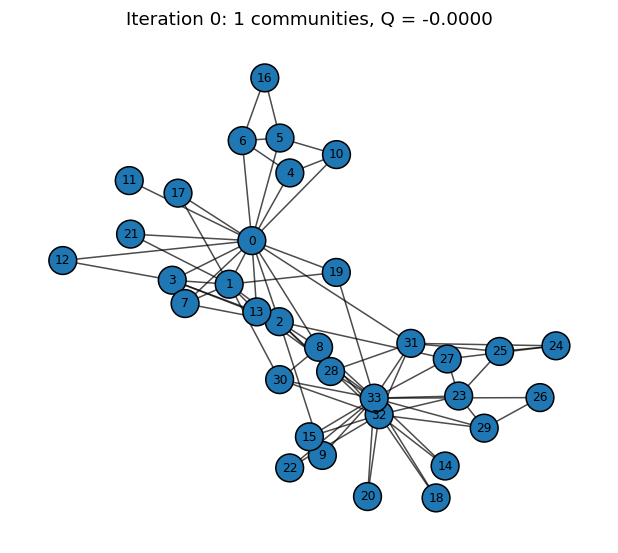

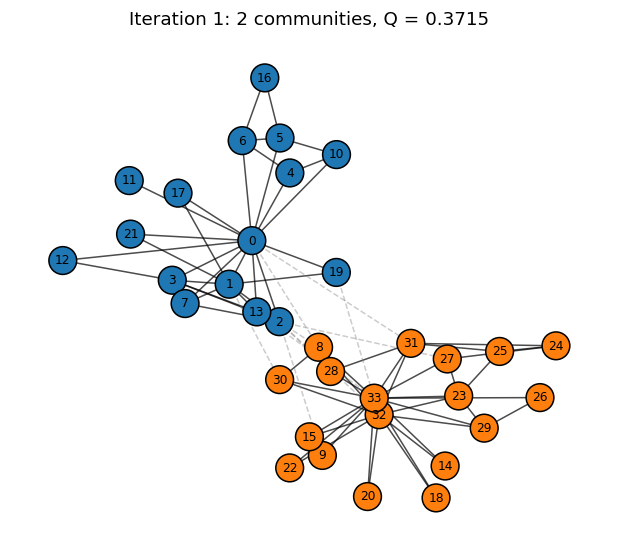

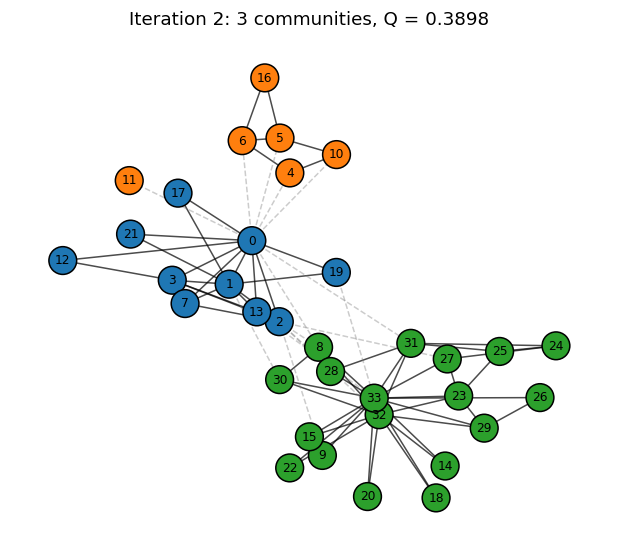

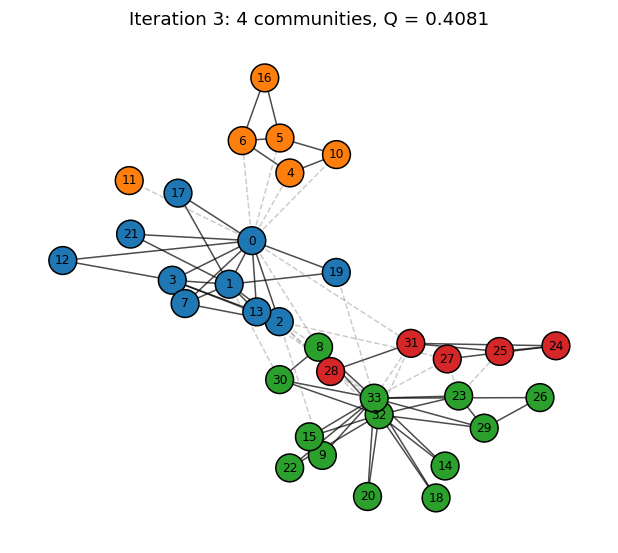

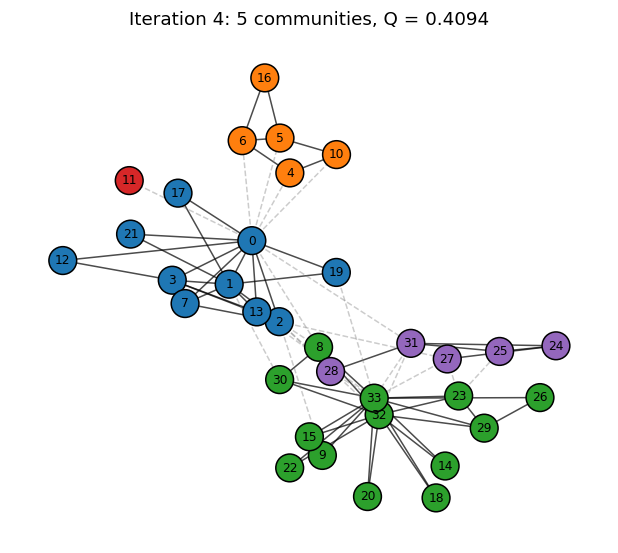

In [5]:
palette = plt.cm.tab10.colors

def draw_partition(G, partition, pos, title, ax):
    color_of = {}
    for ci, c in enumerate(sorted(partition, key=lambda c: min(c))):
        for v in c:
            color_of[v] = palette[ci % 10]
    within = [(u, v) for u, v in G.edges() if color_of[u] == color_of[v]]
    cross  = [(u, v) for u, v in G.edges() if color_of[u] != color_of[v]]
    nx.draw_networkx_edges(G, pos, edgelist=within, ax=ax, alpha=0.7)
    nx.draw_networkx_edges(G, pos, edgelist=cross, ax=ax, alpha=0.4,
                           style="dashed", edge_color="gray")
    nx.draw_networkx_nodes(G, pos, node_color=[color_of[v] for v in G.nodes()],
                           node_size=330, ax=ax, edgecolors="k")
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    ax.set_title(title); ax.axis("off")

for h in history:
    fig, ax = plt.subplots(figsize=(7, 6))
    draw_partition(G, h["partition"], pos,
                   f"Iteration {h['iteration']}: {len(h['partition'])} communities, Q = {h['Q']:.4f}", ax)
    plt.show()

## 7. Node metrics after each split
For every iteration we build $G_t$ = union of subgraphs induced by the communities at that iteration (cross-community edges removed), then compute with NetworkX: degree, betweenness, closeness centrality and clustering coefficient. Results are stored in dictionaries keyed by iteration number.

In [6]:
def graph_after_split(G, partition):
    H = nx.Graph()
    H.add_nodes_from(G.nodes())
    for c in partition:
        H.add_edges_from(G.subgraph(c).edges())
    return H

metrics = {name: {} for name in ["degree", "betweenness", "closeness", "clustering"]}

for h in history:
    H = graph_after_split(G, h["partition"])
    t = h["iteration"]
    metrics["degree"][t]      = nx.degree_centrality(H)
    metrics["betweenness"][t] = nx.betweenness_centrality(H)
    metrics["closeness"][t]   = nx.closeness_centrality(H)
    metrics["clustering"][t]  = nx.clustering(H)

n_iter = len(history)
iters = list(range(n_iter))

# Tidy matrices: rows = nodes, cols = iterations
M = {name: np.array([[metrics[name][t][v] for t in iters] for v in nodes]) for name in metrics}

for name in M:
    print(f"\n{name.capitalize()} (top 5 nodes at each iteration)")
    for t in iters:
        top = sorted(nodes, key=lambda v: -M[name][v, t])[:5]
        print(f"  iter {t}: " + ", ".join(f"{v} ({M[name][v, t]:.3f})" for v in top))


Degree (top 5 nodes at each iteration)
  iter 0: 33 (0.515), 0 (0.485), 32 (0.364), 2 (0.303), 1 (0.273)
  iter 1: 33 (0.455), 0 (0.424), 32 (0.333), 1 (0.242), 3 (0.182)
  iter 2: 33 (0.455), 32 (0.333), 0 (0.273), 1 (0.242), 3 (0.182)
  iter 3: 33 (0.364), 32 (0.303), 0 (0.273), 1 (0.242), 3 (0.182)
  iter 4: 33 (0.364), 32 (0.303), 0 (0.273), 1 (0.242), 3 (0.182)

Betweenness (top 5 nodes at each iteration)
  iter 0: 0 (0.438), 33 (0.304), 32 (0.145), 2 (0.144), 31 (0.138)
  iter 1: 33 (0.147), 0 (0.137), 32 (0.052), 31 (0.029), 23 (0.016)
  iter 2: 33 (0.147), 32 (0.052), 31 (0.029), 0 (0.024), 23 (0.016)
  iter 3: 33 (0.068), 32 (0.032), 0 (0.024), 1 (0.015), 24 (0.006)
  iter 4: 33 (0.068), 32 (0.032), 0 (0.024), 1 (0.015), 24 (0.006)

Closeness (top 5 nodes at each iteration)
  iter 0: 0 (0.569), 2 (0.559), 33 (0.550), 31 (0.541), 8 (0.516)
  iter 1: 33 (0.461), 0 (0.426), 32 (0.381), 23 (0.302), 31 (0.302)
  iter 2: 33 (0.461), 32 (0.381), 23 (0.302), 31 (0.302), 27 (0.283)
  

## 8. Evolution of each metric across iterations
With 34 nodes, line plots get crowded. So the **top-5 nodes** (by average value) are coloured and labelled; the rest are faint grey. A heatmap of all 34 nodes follows below each line plot.

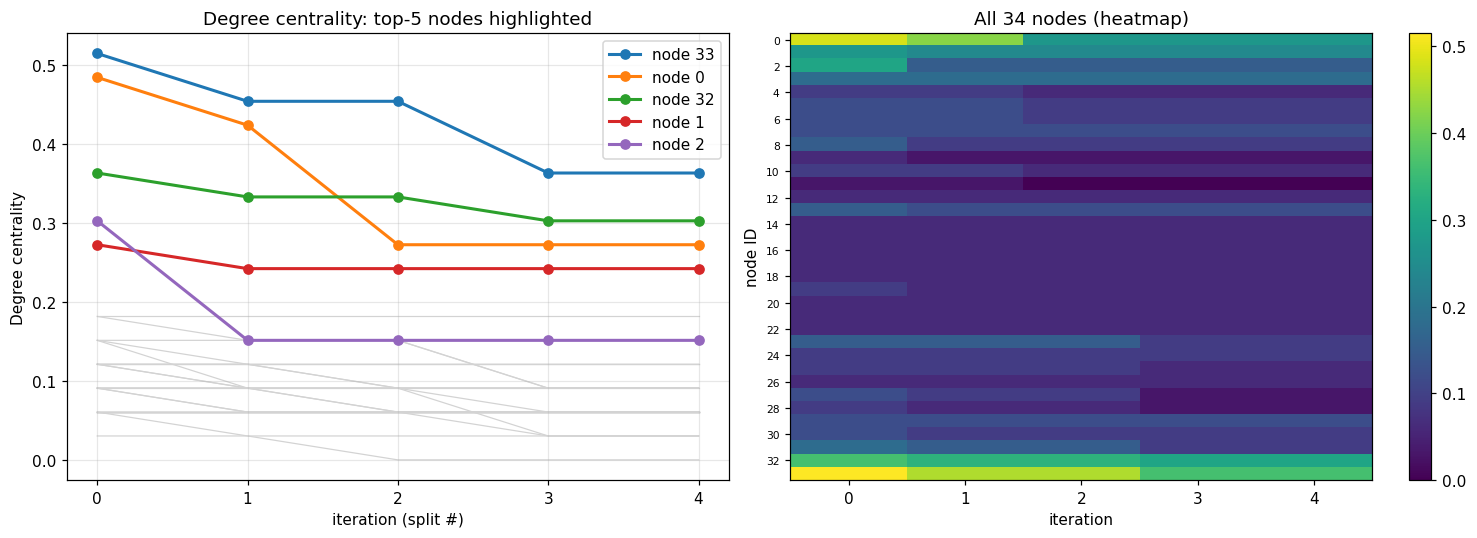

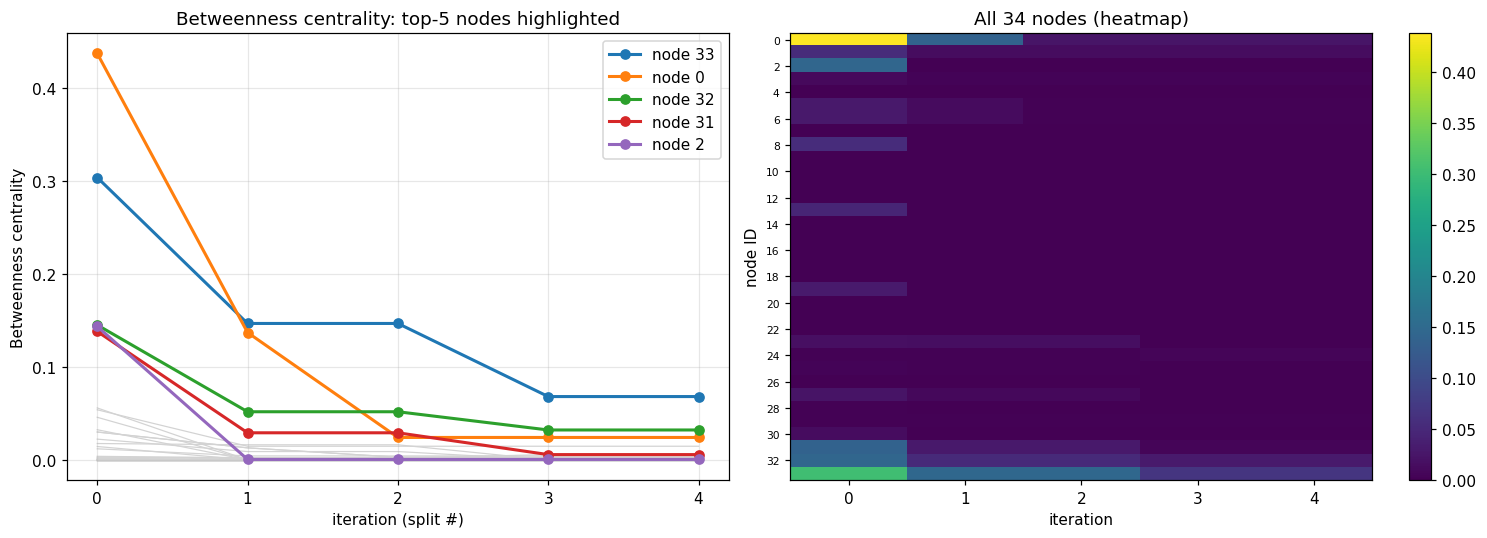

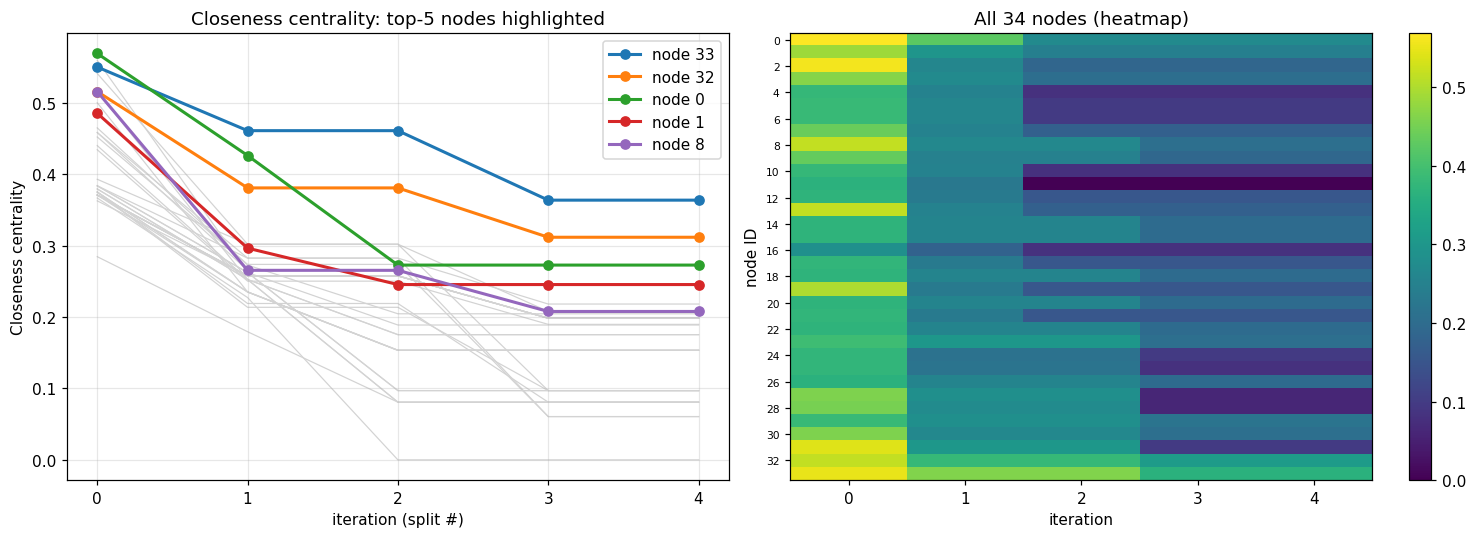

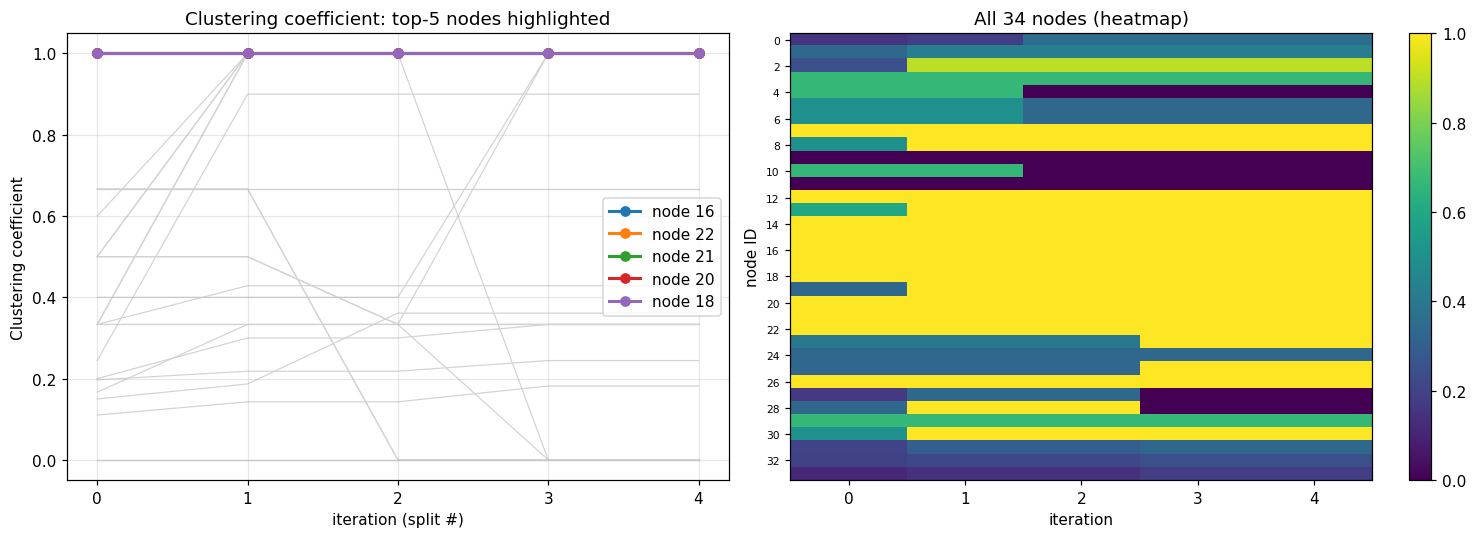

In [7]:
titles = {"degree": "Degree centrality", "betweenness": "Betweenness centrality",
          "closeness": "Closeness centrality", "clustering": "Clustering coefficient"}

for name, mat in M.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.1]})
    ax = axes[0]
    top = np.argsort(-mat.mean(axis=1))[:5]
    for v in nodes:
        if v not in top:
            ax.plot(iters, mat[v], color="lightgray", lw=0.8, zorder=1)
    for ci, v in enumerate(top):
        ax.plot(iters, mat[v], marker="o", lw=2, color=palette[ci], label=f"node {v}", zorder=3)
    ax.set_xticks(iters); ax.set_xlabel("iteration (split #)"); ax.set_ylabel(titles[name])
    ax.set_title(f"{titles[name]}: top-5 nodes highlighted"); ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1]
    im = ax.imshow(mat, aspect="auto", cmap="viridis")
    ax.set_xticks(iters); ax.set_yticks(range(0, n, 2)); ax.set_yticklabels(range(0, n, 2), fontsize=7)
    ax.set_xlabel("iteration"); ax.set_ylabel("node ID"); ax.set_title("All 34 nodes (heatmap)")
    plt.colorbar(im, ax=ax)
    plt.tight_layout(); plt.show()

## 9. Comparison with the real split

In [8]:
truth = {v: G.nodes[v]["club"] for v in nodes}        # 'Mr. Hi' or 'Officer'
print("Ground-truth factions:",
      {c: sum(1 for v in nodes if truth[v] == c) for c in set(truth.values())})

# Compare the FIRST split (a bisection) with the real split
first = history[1]["split"]
Cp, Cm = first[1], first[2]
hi_group = Cp if 0 in Cp else Cm
other    = Cm if 0 in Cp else Cp
mis = [v for v in hi_group if truth[v] != "Mr. Hi"] + [v for v in other if truth[v] != "Officer"]
print(f"First split: group with node 0 has {len(hi_group)} nodes, other has {len(other)}.")
print("Misclassified nodes vs. real split:", sorted(mis))
print(f"Accuracy of first split: {(n - len(mis)) / n:.1%}")

# Modularity of the real split, for reference
real = [[v for v in nodes if truth[v] == c] for c in ["Mr. Hi", "Officer"]]
print(f"\nQ(real split)       = {modularity(real):.4f}")
print(f"Q(first spectral)   = {history[1]['Q']:.4f}")
print(f"Q(final partition)  = {modularity(communities):.4f}")

Ground-truth factions: {'Officer': 17, 'Mr. Hi': 17}
First split: group with node 0 has 16 nodes, other has 18.
Misclassified nodes vs. real split: [8]
Accuracy of first split: 97.1%

Q(real split)       = 0.3582
Q(first spectral)   = 0.3715
Q(final partition)  = 0.4094


## 10. Optional check: Newman's generalized $B^{(g)}$

Strictly, the modularity gain from splitting group $g$ in Newman's paper uses $B^{(g)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in g}B_{il}$ (a diagonal correction), so that $\Delta Q=\frac{1}{4m}s^\top B^{(g)}s$ is *exact*. The handout uses the plain block $B^{(C)}$. The cell below reruns the recursion with the corrected matrix purely for comparison; the main results above follow the handout.

In [9]:
def split_group_generalized(C):
    idx = np.array(C)
    Bc = B[np.ix_(idx, idx)].copy()
    Bc -= np.diag(Bc.sum(axis=1))          # B^(g)_ij = B_ij - delta_ij * sum_l B_il
    lam, u = leading_eigenpair(Bc)
    if lam <= TOL: return None, None
    s = np.where(u > 0, 1, -1)
    Cp, Cm = [int(i) for i in idx[s == 1]], [int(i) for i in idx[s == -1]]
    return (Cp, Cm) if Cp and Cm else (None, None)

part, queue, final_g = [sorted(nodes)], deque([sorted(nodes)]), []
while queue:
    C = queue.popleft()
    Cp, Cm = split_group_generalized(C)
    if Cp is None: final_g.append(C); continue
    queue.extend([Cp, Cm])
print("Generalized-B communities:", len(final_g), " Q =", round(modularity(final_g), 4))
print("Handout-version communities:", len(communities), " Q =", round(modularity(communities), 4))

Generalized-B communities: 5  Q = 0.3776
Handout-version communities: 5  Q = 0.4094


## 11. Discussion

**Result of the algorithm.** The first split gives groups of 16 and 18 nodes (Q = 0.372) and disagrees with Zachary's real split on only node 8 (97.1% agreement). Further splits give 5 communities with final Q = 0.409. Note: for some groups (sizes 10, 5, 13, 5) $\lambda_1>0$ but $u_1$ has a single sign, so the sign rule cannot split them and the recursion stops. This is a known weakness of using the plain block $B^{(C)}$ instead of Newman's corrected $B^{(g)}$ (Section 10).

**Which nodes remain central across splits?**
Nodes **33** and **0** (the two faction leaders) together with **32** have the highest degree centrality at every iteration (see Section 7), with **1** and **3** next. Node 33 is the top node for betweenness and closeness from iteration 1 onwards. Node 0 is the top betweenness node at iteration 0 but loses most of it (0.438 to 0.024) because it was the main bridge between the factions.

**How does community structure influence the metrics?**
* *Degree:* only cross-community edges are deleted, so hubs inside a big community (33, 32) keep most of their degree while bridge nodes (e.g. 2, 8, 13, 31) lose several edges.
* *Betweenness:* drops sharply after the first split (everything that routed between the factions disappears); it stays highest for hubs *inside* their community.
* *Closeness:* NetworkX uses the Wasserman–Faust scaling on disconnected graphs, so values fall as components shrink; central nodes of the biggest remaining component (33, 32) stay on top.
* *Clustering:* nodes already in cliques (7, 12, 13, 14, ...) stay at 1.0. Clustering changes mainly for nodes that sit between communities.
* *Overall:* the splits follow the faction structure, supporting Zachary's observation that friendships predicted the split.

## References
[1] M. E. J. Newman, "Modularity and community structure in networks," *PNAS* 103(23):8577–8582, 2006.
[2] W. W. Zachary, "An information flow model for conflict and fission in small groups," *J. Anthropological Research* 33(4):452–473, 1977.